# SVM Sentiment Classification
Wersja z Pipeline i CV z oryginalnymi parametrami TF-IDF (stop_words=None, trigramy, C=0.3).

In [25]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

In [26]:
import psutil
import os
import time

def print_resource_usage():
    # Pobieramy informacje o bieżącym procesie Pythona
    process = psutil.Process(os.getpid())
    
    # Zużycie pamięci RAM przez notatnik (w MB)
    mem_usage = process.memory_info().rss / (1024 * 1024) 
    
    # Ogólne obciążenie procesora (wszystkie rdzenie)
    cpu_usage = psutil.cpu_percent(interval=0.5) 
    
    print(f"\n[MONITOR ZASOBÓW]")
    print(f"Obciążenie CPU: {cpu_usage}%")
    print(f"Zużycie RAM przez model: {mem_usage:.2f} MB")
    print(f"--------------------------")

In [27]:
df = pd.read_csv('data/processed_reviews.csv')
print("Dataset balance:\n", df['label'].value_counts())

X = df['full_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {len(X_train)}, Test: {len(X_test)}")

Dataset balance:
 label
1    29837
2    29837
0    29837
Name: count, dtype: int64
Train: 71608, Test: 17903


In [28]:
# Oryginalne parametry TF-IDF — empirycznie lepsze na tym datasecie
# stop_words=None: słowa łącznikowe i negacje ('not', 'no') niosą tu info o sentymencie
# ngram_range=(1,3): trigramy pomagają łapać frazy jak 'not good at all'
pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=30000,
        stop_words=None,    # zachowujemy wszystkie słowa
        ngram_range=(1, 3), # unigramy + bigramy + trigramy
        lowercase=True,
        min_df=3
    )),
    ('svm', LinearSVC(
        C=0.3,
        max_iter=3000,
        dual='auto',
        random_state=42
    ))
])

In [29]:
# Walidacja krzyżowa — pipeline gwarantuje brak data leakage
print("Running 5-fold cross-validation...")
cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1_macro', n_jobs=-1)
print(f"CV F1 (macro): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Per-fold: {np.round(cv_scores, 4)}")

Running 5-fold cross-validation...
CV F1 (macro): 0.7628 ± 0.0020
Per-fold: [0.7595 0.7641 0.7615 0.7648 0.7644]


In [30]:
# Trening finalnego modelu na pełnym zbiorze treningowym
start_time = time.time()
pipe.fit(X_train, y_train)
print(f"Training completed in: {time.time() - start_time:.2f} seconds")

y_pred = pipe.predict(X_test)

print("\nSVM Classification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Negative', 'Neutral', 'Positive']
))
print("Stan zasobów po treningu:")
print_resource_usage()

Training completed in: 24.04 seconds

SVM Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.77      0.77      5967
     Neutral       0.69      0.68      0.68      5968
    Positive       0.84      0.86      0.85      5968

    accuracy                           0.77     17903
   macro avg       0.77      0.77      0.77     17903
weighted avg       0.77      0.77      0.77     17903

Stan zasobów po treningu:

[MONITOR ZASOBÓW]
Obciążenie CPU: 11.0%
Zużycie RAM przez model: 1206.89 MB
--------------------------


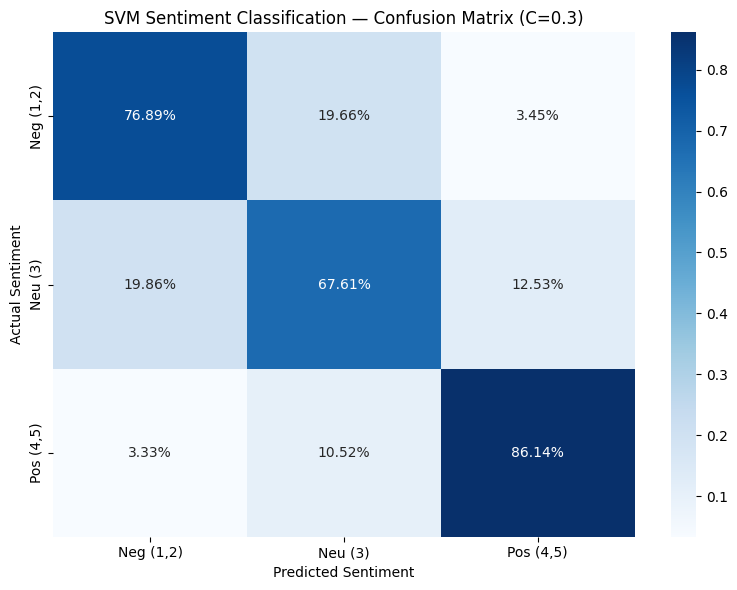

In [31]:
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_percent, annot=True, fmt='.2%', cmap='Blues',
    xticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)'],
    yticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)']
)
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.title('SVM Sentiment Classification — Confusion Matrix (C=0.3)')
plt.tight_layout()
plt.show()